In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf

# Dataset dummy harga rumah
data = pd.DataFrame({
    'luas': [50, 60, 70, 80, 90],
    'harga': [500, 600, 700, 800, 900]
})

X = data[['luas']]
y = data[['harga']]

# Normalisasi fitur dan target
scaler_X = StandardScaler()
scaler_y = StandardScaler()
X_s = scaler_X.fit_transform(X)
y_s = scaler_y.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(X_s, y_s, test_size=0.2, random_state=42)

# Model awal
model_base = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
    tf.keras.layers.Dense(1)
])
model_base.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mse')
model_base.fit(X_train, y_train, epochs=100, verbose=0)

loss_base = model_base.evaluate(X_test, y_test, verbose=0)
print('Loss awal (LR = 0.001):', loss_base)


C:\Users\azure\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:97: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Loss awal (LR = 0.001): 0.15941676497459412


In [2]:
lrs = [0.1, 0.01, 0.001]
histories = {}
loss_results = {}

for lr in lrs:
    tf.random.set_seed(42)
    m = tf.keras.Sequential([
        tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
        tf.keras.layers.Dense(1)
    ])
    m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr), loss='mse')
    h = m.fit(X_train, y_train, epochs=100, verbose=0)
    eval_loss = m.evaluate(X_test, y_test, verbose=0)
    histories[lr] = h.history['loss']
    loss_results[lr] = eval_loss
    print(f'Learning Rate {lr:6.3f} - Final MSE Loss: {eval_loss:.6f}')


Learning Rate  0.100 - Final MSE Loss: 0.004184


Learning Rate  0.010 - Final MSE Loss: 0.031123


Learning Rate  0.001 - Final MSE Loss: 0.770293


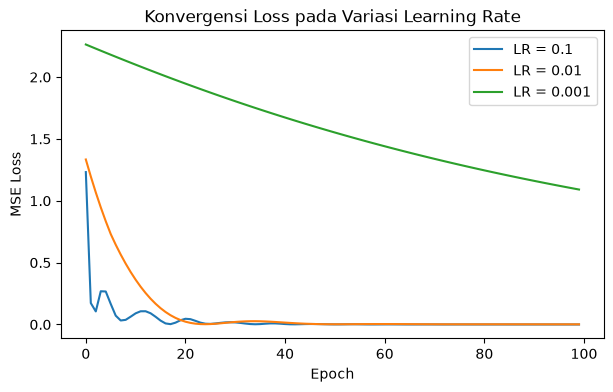

In [3]:
plt.figure(figsize=(7, 4))
for lr in lrs:
    plt.plot(histories[lr], label=f'LR = {lr}')
plt.title('Konvergensi Loss pada Variasi Learning Rate')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.legend()
plt.show()


C:\Users\azure\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:97: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


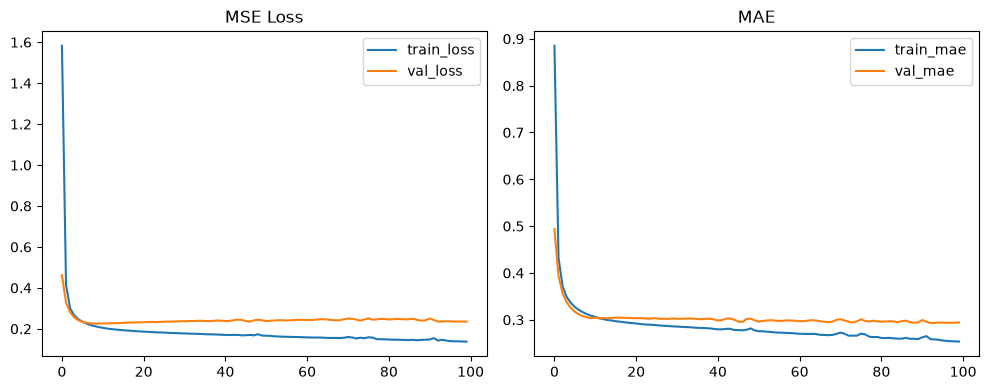

 1/13 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 


RMSE Evaluasi Model MLP: 0.4849


In [4]:
from sklearn.datasets import fetch_california_housing
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import mean_squared_error

# Dataset California Housing
housing = fetch_california_housing()
X_h = housing.data[:2000]
y_h = housing.target[:2000]

# Standarisasi
scaler_h = StandardScaler()
Xs_h = scaler_h.fit_transform(X_h)
X_train_h, X_val_h, y_train_h, y_val_h = train_test_split(Xs_h, y_h, test_size=0.2, random_state=42)

# Model JST regresi
model_mlp = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_h.shape[1],)),
    Dense(32, activation='relu'),
    Dense(1)
])
model_mlp.compile(optimizer=Adam(learning_rate=1e-3), loss='mse', metrics=['mae'])

# Pelatihan model regresi
h_mlp = model_mlp.fit(X_train_h, y_train_h, validation_data=(X_val_h, y_val_h), epochs=100, batch_size=32, verbose=0)

# Visualisasi MSE dan MAE
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(h_mlp.history['loss'], label='train_loss')
plt.plot(h_mlp.history['val_loss'], label='val_loss')
plt.legend()
plt.title('MSE Loss')

plt.subplot(1, 2, 2)
plt.plot(h_mlp.history['mae'], label='train_mae')
plt.plot(h_mlp.history['val_mae'], label='val_mae')
plt.legend()
plt.title('MAE')

plt.tight_layout()
plt.show()

pred_h = model_mlp.predict(X_val_h)
rmse = np.sqrt(mean_squared_error(y_val_h, pred_h))
print(f'RMSE Evaluasi Model MLP: {rmse:.4f}')
